In [1]:
RUN_FINAL = False

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import mlflow

print(sys.executable)
print(Path.cwd())
assert (Path.cwd() / "pyproject.toml").is_file()

d:\campaign-mini\.venv\Scripts\python.exe
d:\campaign-mini


In [2]:
from pathlib import Path
import mlflow
from mlflow import MlflowClient

from tracking import configure_tracking

context = configure_tracking()
experiment_name = "campaign-mini"

experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    experiment_id = mlflow.create_experiment(
        experiment_name,
        artifact_location=context["artifact_uri"],
    )
else:
    if experiment.lifecycle_stage != "active":
        raise ValueError("The existing experiment is not active")

    if (
        experiment.artifact_location.rstrip("/")
        != context["artifact_uri"].rstrip("/")
    ):
        raise ValueError(
            "The existing experiment uses a different artifact location"
        )

    experiment_id = experiment.experiment_id

mlflow.set_experiment(experiment_id=experiment_id)

print("Experiment:", experiment_name)
print("Tracking URI:", context["tracking_uri"])
print("Artifact location:", context["artifact_uri"])

Experiment: campaign-mini
Tracking URI: sqlite:///C:/Users/KISHAN PRAJAPATI/AppData/Local/campaign-mini-state/mlflow.db
Artifact location: file:///C:/Users/KISHAN%20PRAJAPATI/AppData/Local/campaign-mini-state/artifacts


In [3]:
with mlflow.start_run(
    run_name="setup-check",
    tags={"purpose": "setup_check"},
) as run:
    mlflow.log_param("check_kind", "round_trip")
    mlflow.log_metric("check_value", 1.0)
    mlflow.log_text(
        "Tracking round-trip succeeded.",
        "setup_note.txt",
    )

run_id = run.info.run_id

print("Saved run ID:", run_id)

Saved run ID: 445410efc2994bc3b9ecd4e0a8b05ad1


In [4]:
client = MlflowClient(tracking_uri=context["tracking_uri"])
saved = client.get_run(run_id)
note_path = client.download_artifacts(run_id, "setup_note.txt")
note_text = Path(note_path).read_text(encoding="utf-8")

assert saved.info.status == "FINISHED"
assert saved.data.params["check_kind"] == "round_trip"
assert saved.data.metrics["check_value"] == 1.0
assert saved.data.tags["purpose"] == "setup_check"
assert note_text == "Tracking round-trip succeeded."

print("Run ID:", run_id)
print("Status:", saved.info.status)
print("Parameter:", saved.data.params["check_kind"])
print("Metric:", saved.data.metrics["check_value"])
print("Tag:", saved.data.tags["purpose"])
print("Artifact:", note_text)
print("All setup checks passed.")

Run ID: 445410efc2994bc3b9ecd4e0a8b05ad1
Status: FINISHED
Parameter: round_trip
Metric: 1.0
Tag: setup_check
Artifact: Tracking round-trip succeeded.
All setup checks passed.


In [5]:
import hashlib

ROOT = Path.cwd()
assert (ROOT / "pyproject.toml").is_file(), "Open the campaign-mini folder"

if (ROOT / "results/final_result.json").exists():
    raise RuntimeError(
        "Final access already started; use the recorded results"
    )

for folder in ["data/raw", "data/holdout", "results/figures"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

RAW = ROOT / "data/raw/bank-additional-full.csv"

NUMERIC = ["age", "previous"]
CATEGORICAL = [
    "job", "marital", "education", "housing", "loan", "poutcome"
]
FEATURES = NUMERIC + CATEGORICAL

In [6]:
assert RAW.is_file(), f"Place the downloaded CSV at {RAW}"

source_sha256 = hashlib.sha256(RAW.read_bytes()).hexdigest()
source = pd.read_csv(
    RAW,
    sep=";",
    keep_default_na=False,
    dtype="string",
)

assert len(source) == 41188, "Check the dataset variant"

missing = set(FEATURES + ["y"]) - set(source.columns)
assert not missing, f"Missing columns: {missing}"
for column in FEATURES + ["y"]:
    source[column] = source[column].str.strip().replace("", pd.NA)

assert source["y"].isin(["yes", "no"]).all(), "Invalid or missing target"

for column in NUMERIC:
    source[column] = pd.to_numeric(
        source[column], errors="raise"
    ).astype("float64")

    values = source[column].dropna()
    assert np.isfinite(values).all(), f"Infinite values in {column}"
    assert (values >= 0).all(), f"Negative values in {column}"

source.insert(0, "record_id", range(len(source)))

print("Source SHA-256:", source_sha256)
print("Source rows:", len(source))

Source SHA-256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8
Source rows: 41188


In [7]:
from sklearn.model_selection import train_test_split

n = len(source)
train_size = 7 * n // 10
dev_size = 85 * n // 100 - train_size

train, remaining = train_test_split(
    source,
    train_size=train_size,
    shuffle=False,
)

dev, final = train_test_split(
    remaining,
    train_size=dev_size,
    shuffle=False,
)

del remaining

assert (len(train), len(dev), len(final)) == (28831, 6178, 6179)

split_ids = pd.concat(
    [
        train[["record_id"]].assign(split="train"),
        dev[["record_id"]].assign(split="dev"),
        final[["record_id"]].assign(split="final"),
    ],
    ignore_index=True,
)

assert split_ids["record_id"].is_unique

pd.testing.assert_series_equal(
    split_ids["record_id"],
    source["record_id"].reset_index(drop=True),
)

split_ids.to_csv(ROOT / "data/split_ids.csv", index=False)

print(split_ids["split"].value_counts(sort=False))

split
train    28831
dev       6178
final     6179
Name: count, dtype: int64


In [8]:
final[["record_id"] + FEATURES].to_csv(
    ROOT / "data/holdout/final_features.csv",
    index=False,
)

final_labels = final[["record_id", "y"]].copy()
final_labels["y"] = (
    final_labels["y"]
    .map({"no": 0, "yes": 1})
    .astype("int64")
)

final_labels.to_csv(
    ROOT / "data/holdout/final_labels.csv",
    index=False,
)
assert hashlib.sha256(RAW.read_bytes()).hexdigest() == source_sha256

del final_labels, final, source

print("Final files saved. Continue exploration with train only.")

Final files saved. Continue exploration with train only.


In [9]:
train_y = train["y"].map({"no": 0, "yes": 1}).astype("int64")

numeric_summary = train[NUMERIC].describe().T

unknown_counts = train[CATEGORICAL].eq("unknown").sum()

category_summary = pd.DataFrame({
    "unknown_count": unknown_counts,
    "unknown_pct": 100 * unknown_counts / len(train),
    "missing_count": train[CATEGORICAL].isna().sum(),
})

outcome_summary = (
    train.assign(subscribed=train_y)
    .groupby("poutcome", dropna=False)
    .agg(
        records=("subscribed", "size"),
        subscribers=("subscribed", "sum"),
        subscription_rate=("subscribed", "mean"),
    )
)

print(numeric_summary)
print(category_summary)
print(outcome_summary)

            count       mean       std   min   25%   50%   75%   max
age       28831.0  40.177483  9.335439  18.0  33.0  39.0  47.0  95.0
previous  28831.0   0.035899  0.192456   0.0   0.0   0.0   0.0   3.0
           unknown_count  unknown_pct  missing_count
job                  249     0.863654              0
marital               49     0.169956              0
education           1183     4.103222              0
housing              694     2.407131              0
loan                 694     2.407131              0
poutcome               0          0.0              0
             records  subscribers  subscription_rate
poutcome                                            
failure          952           56           0.058824
nonexistent    27829         1543           0.055446
success           50            7           0.140000


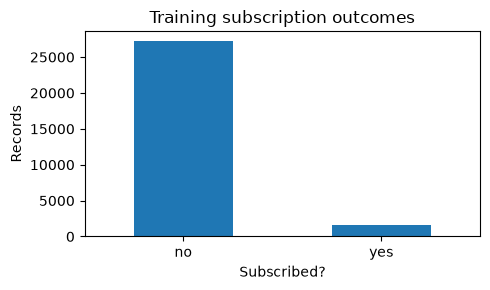

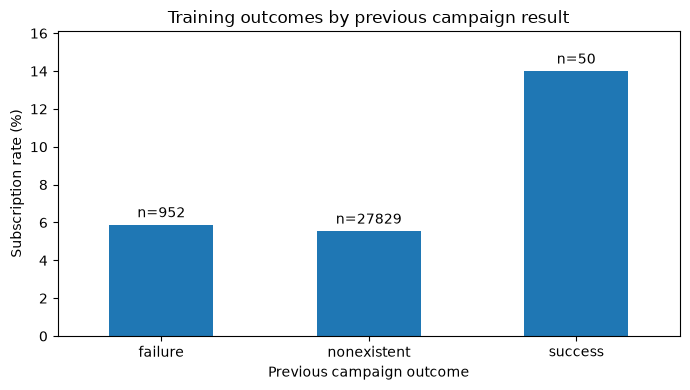

In [10]:
class_counts = (
    train["y"]
    .value_counts()
    .reindex(["no", "yes"], fill_value=0)
)
fig, ax = plt.subplots(figsize=(5, 3))
class_counts.plot.bar(ax=ax, rot=0)

ax.set(
    title="Training subscription outcomes",
    xlabel="Subscribed?",
    ylabel="Records",
)

fig.tight_layout()
fig.savefig(
    ROOT / "results/figures/train_class_counts.png",
    dpi=150,
)
plt.show()
plt.close(fig)


fig, ax = plt.subplots(figsize=(7, 4))

(100 * outcome_summary["subscription_rate"]).plot.bar(
    ax=ax,
    rot=0,
)

ax.bar_label(
    ax.containers[0],
    labels="n=" + outcome_summary["records"].astype(str),
    padding=3,
)
ax.margins(y=0.15)

ax.set(
    title="Training outcomes by previous campaign result",
    xlabel="Previous campaign outcome",
    ylabel="Subscription rate (%)",
)

fig.tight_layout()
fig.savefig(
    ROOT / "results/figures/train_poutcome_rate.png",
    dpi=150,
)
plt.show()
plt.close(fig)

In [11]:
from helpers import FEATURES, prepare_inputs

train_ids, X_train, y_train = prepare_inputs(train, mode="labeled")
dev_ids, X_dev, y_dev = prepare_inputs(dev, mode="labeled")

assert len(train_ids) == len(X_train) == len(y_train)
assert len(dev_ids) == len(X_dev) == len(y_dev)
assert X_train.columns.tolist() == FEATURES
assert X_dev.columns.tolist() == FEATURES

print("Training inputs:", X_train.shape)
print("Development inputs:", X_dev.shape)
print("Training target values:", y_train.unique())

Training inputs: (28831, 8)
Development inputs: (6178, 8)
Training target values: [0 1]


In [12]:
import importlib

import numpy as np
import pandas as pd

import helpers

importlib.reload(helpers)
from helpers import FEATURES, NUMERIC, build_pipeline, prepare_inputs

In [13]:
for original, ids, X, y in [
    (train, train_ids, X_train, y_train),
    (dev, dev_ids, X_dev, y_dev),
]:
    assert len(original) == len(ids) == len(X) == len(y)
    assert list(X.columns) == FEATURES
    assert ids.index.equals(original.index)
    assert ids.index.equals(X.index) and X.index.equals(y.index)
    assert ids.tolist() == original['record_id'].tolist()
    assert not {'record_id', 'y'} & set(X.columns)

assert not train_ids.isin(dev_ids).any()
print('Train shape:', X_train.shape, 'Development shape:', X_dev.shape)
print(pd.DataFrame({
    'dtype': X_train.dtypes.astype(str),
    'missing_in_train': X_train.isna().sum(),
}))

Train shape: (28831, 8) Development shape: (6178, 8)
             dtype  missing_in_train
age        float64                 0
previous   float64                 0
job         object                 0
marital     object                 0
education   object                 0
housing     object                 0
loan        object                 0
poutcome    object                 0


In [14]:
toy = pd.DataFrame({
    'record_id': [0, 1, 2, 3],
    'age': [20, 40, np.nan, 60],
    'previous': [0, 1, 2, 3],
    'job': ['admin.', 'technician', None, 'admin.'],
    'marital': ['single', 'married', 'single', 'married'],
    'education': ['high.school', 'university.degree', 'high.school', 'high.school'],
    'housing': ['yes', 'no', 'yes', 'no'],
    'loan': ['no', 'no', 'yes', 'no'],
    'poutcome': ['nonexistent', 'failure', 'success', 'nonexistent'],
    'y': ['no', 'yes', 'no', 'yes'],
})
_, X_toy, y_toy = prepare_inputs(toy, mode='labeled')
demo_model = build_pipeline('lr_c1')
demo_model.fit(X_toy, y_toy)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepare', ...), ('classify', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['age','previous','job',...,'housing','loan','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns t

In [15]:
prep = demo_model.named_steps['prepare']
num = prep.named_transformers_['num']
imputer = num.named_steps['impute']
scaler = num.named_steps['scale']
encoder = prep.named_transformers_['cat'].named_steps['encode']

expected_medians = X_toy[NUMERIC].median()
filled = X_toy[NUMERIC].fillna(expected_medians)
np.testing.assert_allclose(imputer.statistics_, expected_medians)
np.testing.assert_allclose(scaler.mean_, filled.mean())
np.testing.assert_allclose(scaler.var_, filled.var(ddof=0))

print(pd.DataFrame({
    'median': imputer.statistics_,
    'mean_after_imputation': scaler.mean_,
    'variance_after_imputation': scaler.var_,
    'scale': scaler.scale_,
}, index=NUMERIC))
print('Learned category lists:', encoder.categories_)
transformed = prep.transform(X_toy)
print('Transformed shape:', transformed.shape)
print('Transformed names:', prep.get_feature_names_out())
assert transformed.shape[1] == len(prep.get_feature_names_out())

          median  mean_after_imputation  variance_after_imputation      scale
age         40.0                   40.0                     200.00  14.142136
previous     1.5                    1.5                       1.25   1.118034
Learned category lists: [array(['admin.', 'technician', 'unknown'], dtype=object), array(['married', 'single'], dtype=object), array(['high.school', 'university.degree'], dtype=object), array(['no', 'yes'], dtype=object), array(['no', 'yes'], dtype=object), array(['failure', 'nonexistent', 'success'], dtype=object)]
Transformed shape: (4, 16)
Transformed names: ['num__age' 'num__previous' 'cat__job_admin.' 'cat__job_technician'
 'cat__job_unknown' 'cat__marital_married' 'cat__marital_single'
 'cat__education_high.school' 'cat__education_university.degree'
 'cat__housing_no' 'cat__housing_yes' 'cat__loan_no' 'cat__loan_yes'
 'cat__poutcome_failure' 'cat__poutcome_nonexistent'
 'cat__poutcome_success']


In [16]:
future_toy = toy.iloc[[0]].drop(columns='y').assign(
    record_id=99, age=1_000_000, job='new_job',
)
_, X_future_toy, _ = prepare_inputs(future_toy, mode='predict')
statistics_before = [
    imputer.statistics_.copy(), scaler.mean_.copy(), scaler.var_.copy(),
]
probabilities = demo_model.predict_proba(X_future_toy)
print('Toy classes:', demo_model.classes_)
print('Toy probabilities:', probabilities)
assert np.isfinite(probabilities).all()
for actual, expected in zip(
    [imputer.statistics_, scaler.mean_, scaler.var_], statistics_before,
):
    np.testing.assert_allclose(actual, expected)
np.testing.assert_allclose(
    probabilities,
    demo_model.predict_proba(X_future_toy.loc[:, FEATURES[::-1]]),
)
print('Toy boundary checks passed.')

Toy classes: [0 1]
Toy probabilities: [[0. 1.]]
Toy boundary checks passed.
